# Previsão diária | Validação temporal

A fonte são medições horárias da Alura. A série diária contém somente dias com 24 medições após a remoção de duplicatas. Os últimos 20% dos dias completos formam um teste reservado; os 90 últimos dias do trecho anterior servem para escolher o método. Métricas são calculadas pelo código, sem valores copiados manualmente.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from forecast import DATA_URL, preparar_dados, experimento

serie, dias_excluidos = preparar_dados(pd.read_csv(DATA_URL))
validacao, final = experimento(serie)
print(f"Dias completos: {len(serie)}; excluídos por incompletude: {dias_excluidos}")
print("Desenvolvimento, validação, treino total, teste:", final["tamanhos"])
display(validacao.round(2))

Dias completos: 696; excluídos por incompletude: 34
Desenvolvimento, validação, treino total, teste: (466, 90, 556, 140)


,modelo,RMSE,MAE,outliers_removidos_no_ajuste
0,prophet_anual,6605.41,5199.87,0
1,prophet_anual_sem_outliers,6609.79,5128.42,54
2,prophet_padrao,6992.02,5798.12,0
3,ultimo_dia_semana,9549.77,7544.33,0


Importing plotly failed. Interactive plots will not work.
10:44:51 - cmdstanpy - INFO - Chain [1] start processing
10:44:51 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
10:44:51 - cmdstanpy - INFO - Chain [1] start processing
10:44:51 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
10:44:51 - cmdstanpy - INFO - Chain [1] start processing
10:44:51 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is ena

## Escolha do modelo

A referência ingênua repete para todo o horizonte o último valor disponível de cada dia da semana no treino. As alternativas são Prophet padrão, Prophet com sazonalidade anual e Prophet anual após remoção de observações fora do intervalo ajustado **somente no treino**. A menor RMSE de validação define um único modelo para o teste. A remoção de picos pode descartar demanda legítima; ela é uma hipótese a avaliar, não uma melhoria garantida.

Modelo escolhido pela validação: prophet_anual
Teste final: {'RMSE': 6160.98, 'MAE': 4937.92}
Outliers removidos no treino final: 0


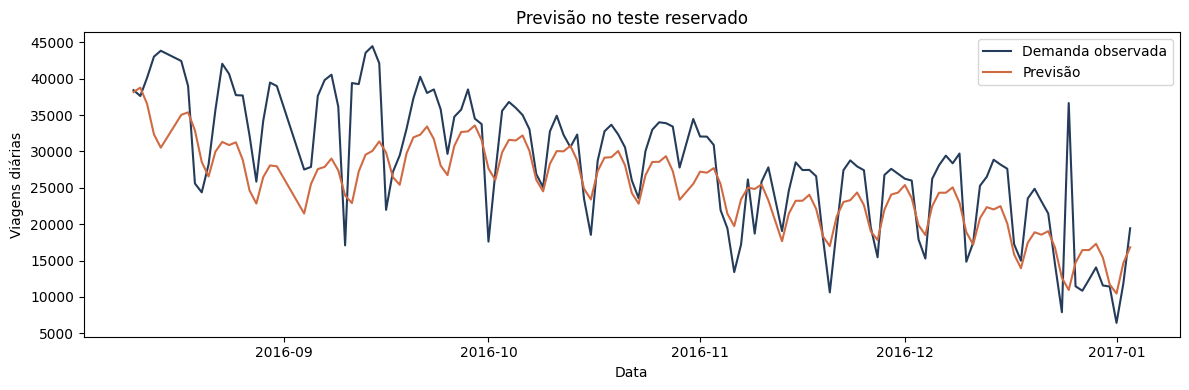

In [4]:
print("Modelo escolhido pela validação:", final["modelo"])
print("Teste final:", {chave: round(valor, 2) for chave, valor in final["teste"].items()})
print("Outliers removidos no treino final:", final["outliers_removidos_no_treino"])
previsoes = final["previsoes"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(previsoes["ds"], previsoes["y"], label="Demanda observada", color="#243c5a")
ax.plot(previsoes["ds"], previsoes["yhat"], label="Previsão", color="#d06a43")
ax.legend()
ax.set(title="Previsão no teste reservado", xlabel="Data", ylabel="Viagens diárias")
plt.tight_layout()
plt.show()

## Limites da avaliação

Há um único recorte de validação e um único teste. A sazonalidade anual é estimada com histórico inferior a dois anos e pode ser instável. Dias incompletos foram removidos, o que pode alterar a distribuição da demanda. Um próximo passo seria avaliar múltiplas origens temporais e um período maior, como sugerem os [diagnósticos do Prophet](https://facebook.github.io/prophet/docs/diagnostics.html). Não se deve inferir desempenho operacional contínuo a partir de um único recorte histórico.